# Perfil do eleitorado × voto por partido, por município

Cruza o voto por partido (Presidente e Deputado Federal) com a escolaridade do
eleitorado e a renda da vizinhança, em um município.

- **Por local de votação** (`perfil_voto_local`): voto e escolaridade são os
  publicados pelo TSE, sem estimativa. A escolaridade é a do cadastro eleitoral.
- **Por setor censitário** (`perfil_voto_setor`): a renda é a do Censo 2022
  (rendimento do responsável pelo domicílio). O voto e a escolaridade são
  **estimados**, distribuídos dos locais para os setores pela matriz de pesos da
  etapa 03.

As tabelas vêm de `scripts/10_perfil_voto_municipio.py`. Para outro município,
rodar as etapas 09, 03 e 10 com o código dele e trocar `CD_MUN` abaixo.

**Como ler os resultados**

- Os dados são agregados. Eles mostram **onde** cada partido vai melhor, não como
  vota cada pessoa: um partido forte nos locais mais escolarizados não é
  necessariamente o mais votado entre os eleitores escolarizados.
- A escolaridade do cadastro é a declarada no alistamento e quase nunca é
  atualizada, então subestima a escolaridade atual.
- Na tabela por setor, os setores atendidos pelo mesmo local repetem o voto dele.
  A variação independente vem dos locais, não dos setores; por isso o erro padrão
  das regressões por setor é agrupado pelo local dominante.
- O voto para deputado segue o candidato e o reduto dele. A soma por partido
  mistura bases pessoais diferentes.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.patches import Patch

CD_MUN = "2211001"  # Teresina-PI
ANO = 2022
PC_MINIMO_PARTIDO = 0.03  # partido abaixo disso entra em "Outros"

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
ANALISE = RAIZ / "dados" / "04_analise" / CD_MUN
SETORES_GPKG = RAIZ / "dados" / "01_bruto" / "aux" / "setores" / f"setores_{CD_MUN}.gpkg"
CRS_METRICO = 5880  # SIRGAS 2000 / Brazil Polyconic

CODIGOS_NAO_CANDIDATO = (95, 96, 97)
DISPUTAS = {
    "pres_t1": "Presidente, 1º turno",
    "pres_t2": "Presidente, 2º turno",
    "depfed_t1": "Deputado Federal",
}
QUINTIS = [f"Q{i}" for i in range(1, 6)]

pd.set_option("display.max_columns", 40)

In [2]:
# ==== Aparência dos gráficos ==================================================
COR = "#2a78d6"  # série única
COR_TINTA = "#0b0b0b"
COR_TINTA_2 = "#52514e"
COR_SUAVE = "#898781"
COR_GRADE = "#e1e0d9"
COR_EIXO = "#c3c2b7"
COR_FUNDO = "#fcfcfb"
COR_SEM_DADO = "#f0efec"
RAMPA = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]  # um matiz, claro -> escuro

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO, "axes.facecolor": COR_FUNDO, "savefig.facecolor": COR_FUNDO,
    "figure.dpi": 110,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": COR_TINTA, "axes.labelcolor": COR_TINTA_2,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": COR_EIXO, "ytick.color": COR_EIXO,
    "xtick.labelcolor": COR_SUAVE, "ytick.labelcolor": COR_SUAVE,
    "axes.edgecolor": COR_EIXO, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": COR_GRADE, "grid.linewidth": 0.6,
})


def numero(valor: float, casas: int = 1) -> str:
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## Dados

In [3]:
local_todos = pd.read_parquet(ANALISE / f"perfil_voto_local_{ANO}.parquet")
setor_todos = pd.read_parquet(ANALISE / f"perfil_voto_setor_{ANO}.parquet")
SIGLA = pd.read_parquet(ANALISE / f"partidos_{ANO}.parquet").set_index("nr_partido")["sg_partido"].to_dict()
DISPUTAS = {d: nome for d, nome in DISPUTAS.items() if f"{d}_qt_comparecimento" in local_todos.columns}

# Locais com eleitorado próprio no cadastro (voto em trânsito e presos provisórios
# não têm) e setores que receberam voto na distribuição.
local = local_todos.loc[~local_todos["flag_especial"] & local_todos["qt_eleitores_perfil"].gt(0)].copy()
setor = setor_todos.dropna(subset=[f"{next(iter(DISPUTAS))}_qt_comparecimento", "renda_media_resp"]).copy()

local["log_renda_area"] = np.log(local["renda_media_resp_area"])
setor["log_renda"] = np.log(setor["renda_media_resp"])

print(f"{len(local)} locais de votação, {numero(local['qt_eleitores_perfil'].sum(), 0)} eleitores no cadastro")
print(f"{len(setor)} setores com voto estimado e renda ({len(setor_todos)} no município), "
      f"atendidos por {setor['id_local_dominante'].nunique()} locais dominantes")

296 locais de votação, 589.264 eleitores no cadastro
1379 setores com voto estimado e renda (1531 no município), atendidos por 273 locais dominantes


In [4]:
def votos_por_partido(df: pd.DataFrame, disputa: str) -> pd.DataFrame:
    """Votos de cada partido (colunas = sigla), do maior para o menor.

    Partidos com menos de `PC_MINIMO_PARTIDO` dos votos válidos do município
    são somados em "Outros".
    """
    prefixo = f"{disputa}_qt_votos_"
    numeros = [int(c.removeprefix(prefixo)) for c in df.columns if c.startswith(prefixo)]
    numeros = [nr for nr in numeros if nr not in CODIGOS_NAO_CANDIDATO]
    votos = df[[f"{prefixo}{nr}" for nr in numeros]].set_axis(numeros, axis=1).fillna(0)

    # O corte usa sempre o total por local (observado), para a lista de
    # partidos ser a mesma nas tabelas por local e por setor.
    total = local_todos[[f"{prefixo}{nr}" for nr in numeros]].set_axis(numeros, axis=1).sum()
    total = total.sort_values(ascending=False)
    grandes = total.index[total / total.sum() >= PC_MINIMO_PARTIDO]

    saida = votos[grandes].rename(columns=SIGLA)
    if len(grandes) < len(numeros):
        saida["Outros"] = votos.drop(columns=grandes).sum(axis=1)
    return saida


resumo = pd.concat(
    {
        nome: (100 * votos_por_partido(local_todos, d).sum() / votos_por_partido(local_todos, d).sum().sum())
        for d, nome in DISPUTAS.items()
    },
    axis=1,
)
resumo.style.format(precision=1, decimal=",", na_rep="")

,"Presidente, 1º turno","Presidente, 2º turno",Deputado Federal
PT,"62,4","66,4","25,2"
PL,"28,6","33,6","3,6"
PDT,"4,1",,
MDB,"3,8",,
Outros,"1,1",,"9,7"
PP,,,"17,1"
PSD,,,"14,1"
REPUBLICANOS,,,"12,4"
SOLIDARIEDADE,,,"8,9"
UNIÃO,,,"5,8"


Percentual dos votos válidos de cada partido no município. Daqui em diante, cada
partido da lista é analisado em separado; "Outros" fica só nas tabelas.

## Eleitorado e renda

In [5]:
GRUPOS_ESC = {
    "pc_esc_ate_fund_incompleto": "Até fundamental incompleto",
    "pc_esc_fund_completo": "Fundamental completo ou médio incompleto",
    "pc_esc_medio_completo": "Médio completo ou superior incompleto",
    "pc_esc_superior": "Superior completo",
}
CODIGOS_ESC = {
    "pc_esc_ate_fund_incompleto": (1, 2, 3), "pc_esc_fund_completo": (4, 5),
    "pc_esc_medio_completo": (6, 7), "pc_esc_superior": (8,),
}
total_esc = local[[f"qt_esc_{cd}" for cd in range(1, 9)]].sum()
escolaridade = pd.DataFrame({
    "eleitores": {GRUPOS_ESC[g]: int(sum(total_esc[f"qt_esc_{cd}"] for cd in cds)) for g, cds in CODIGOS_ESC.items()},
})
escolaridade["% do eleitorado"] = (100 * escolaridade["eleitores"] / escolaridade["eleitores"].sum()).round(1)
escolaridade

,eleitores,% do eleitorado
Até fundamental incompleto,140516,23.8
Fundamental completo ou médio incompleto,137337,23.3
Médio completo ou superior incompleto,234563,39.8
Superior completo,76848,13.0


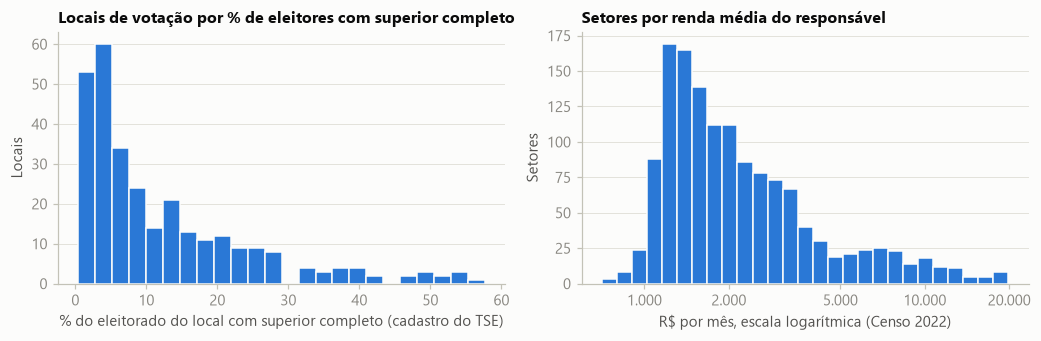

,pc_esc_superior,idade_media,pc_feminino,renda_media_resp_area
mean,0.125,42.176,0.546,3012.873
std,0.123,5.476,0.024,2344.191
min,0.004,24.497,0.426,991.735
50%,0.077,42.894,0.548,2145.686
max,0.577,56.515,0.616,16664.253


In [6]:
fig, (eixo_esc, eixo_renda) = plt.subplots(1, 2, figsize=(9.6, 3.2))

eixo_esc.hist(100 * local["pc_esc_superior"], bins=24, color=COR, edgecolor=COR_FUNDO, linewidth=1)
eixo_esc.set_title("Locais de votação por % de eleitores com superior completo")
eixo_esc.set_xlabel("% do eleitorado do local com superior completo (cadastro do TSE)")
eixo_esc.set_ylabel("Locais")

eixo_renda.hist(setor["renda_media_resp"], bins=np.geomspace(setor["renda_media_resp"].min(), setor["renda_media_resp"].max(), 28),
                color=COR, edgecolor=COR_FUNDO, linewidth=1)
eixo_renda.set_xscale("log")
marcas = [1000, 2000, 5000, 10000, 20000]
eixo_renda.set_xticks(marcas, [numero(m, 0) for m in marcas])
eixo_renda.minorticks_off()
eixo_renda.set_title("Setores por renda média do responsável")
eixo_renda.set_xlabel("R$ por mês, escala logarítmica (Censo 2022)")
eixo_renda.set_ylabel("Setores")

for eixo in (eixo_esc, eixo_renda):
    eixo.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

local[["pc_esc_superior", "idade_media", "pc_feminino", "renda_media_resp_area"]].describe().loc[["mean", "std", "min", "50%", "max"]].round(3)

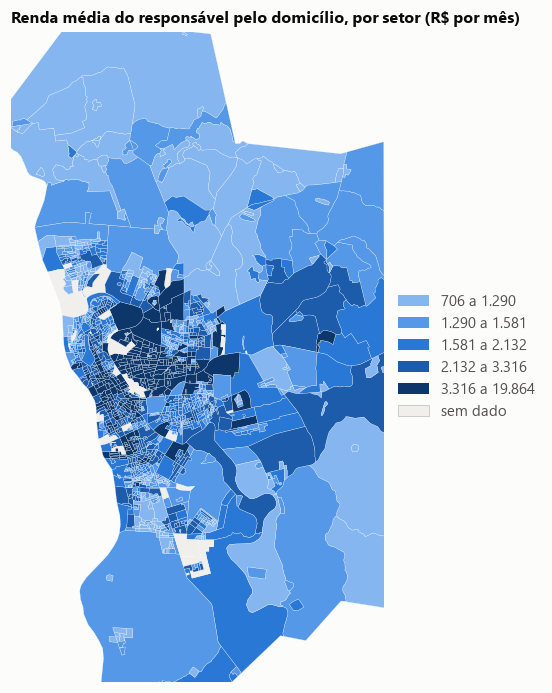

In [7]:
def mapa_em_classes(gdf: gpd.GeoDataFrame, coluna: str, titulo: str, formato) -> None:
    """Mapa por setor em 5 classes (quintis), recortado na área urbana."""
    classes, cortes = pd.qcut(gdf[coluna], 5, labels=False, retbins=True)
    cores = classes.map(lambda c: COR_SEM_DADO if pd.isna(c) else RAMPA[int(c)])

    fig, eixo = plt.subplots(figsize=(7.2, 6.4))
    gdf.plot(ax=eixo, color=cores, edgecolor=COR_FUNDO, linewidth=0.15)
    # Recorte nos setores pequenos (urbanos): os rurais, enormes, encolheriam a cidade.
    xmin, ymin, xmax, ymax = gdf.loc[gdf["area_km2"] < 2].total_bounds
    eixo.set_xlim(xmin, xmax)
    eixo.set_ylim(ymin, ymax)
    eixo.set_axis_off()
    eixo.set_title(titulo)
    legenda = [
        Patch(facecolor=RAMPA[i], label=f"{formato(cortes[i])} a {formato(cortes[i + 1])}") for i in range(5)
    ] + [Patch(facecolor=COR_SEM_DADO, edgecolor=COR_EIXO, linewidth=0.5, label="sem dado")]
    eixo.legend(handles=legenda, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, labelcolor=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


setores_geo = gpd.read_file(SETORES_GPKG).rename(columns={"CD_SETOR": "cd_setor"})
setores_geo["area_km2"] = setores_geo.to_crs(CRS_METRICO).area / 1e6
mapa = setores_geo.merge(
    setor_todos[["cd_setor", "renda_media_resp", "pc_esc_superior"]], on="cd_setor", how="left"
)

mapa_em_classes(mapa, "renda_media_resp", "Renda média do responsável pelo domicílio, por setor (R$ por mês)",
                lambda v: numero(v, 0))

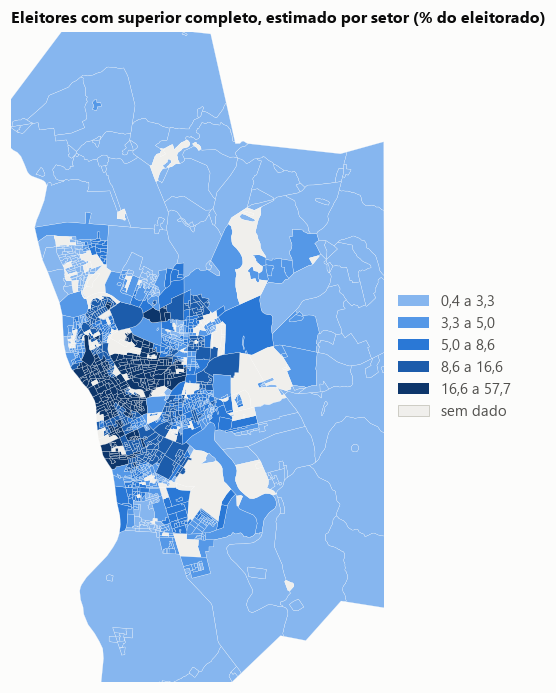

In [8]:
mapa_em_classes(mapa.assign(pc=100 * mapa["pc_esc_superior"]), "pc",
                "Eleitores com superior completo, estimado por setor (% do eleitorado)",
                lambda v: numero(v, 1))

## Voto × escolaridade, por local de votação

Os locais são ordenados pelo percentual de eleitores com superior completo e
divididos em cinco grupos de mesmo tamanho (Q1 = locais menos escolarizados,
Q5 = mais escolarizados). Em cada grupo, o percentual é a soma dos votos do
partido sobre a soma dos votos válidos.

% com superior completo em cada grupo de locais:
  Q1: 0,4 a 3,1 | Q2: 3,2 a 5,6 | Q3: 5,8 a 10,7 | Q4: 11,1 a 20,7 | Q5: 21,0 a 57,7


,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"74,6","68,8","63,9","58,8","48,4","62,4"
PL,"19,3","23,6","27,2","30,9","40,3","28,6"
PDT,"2,6","3,4","4,1","4,8","5,2","4,1"
MDB,"2,5","3,1","3,7","4,3","4,9","3,8"
Outros,"1,0","1,0","1,2","1,2","1,3","1,1"


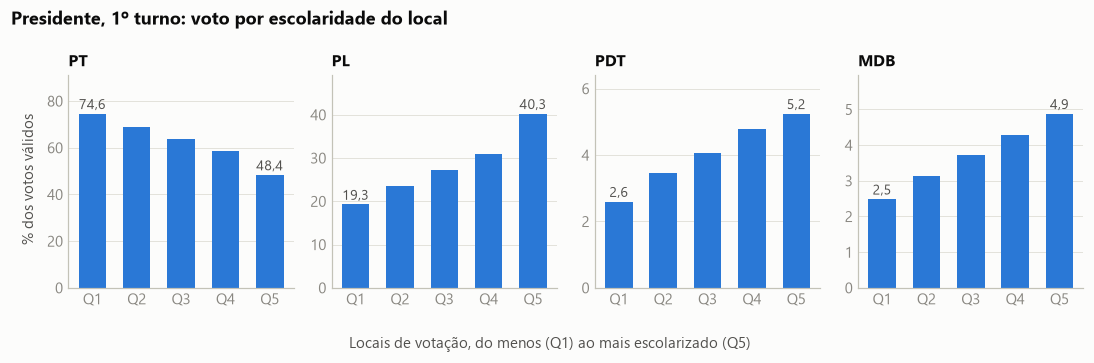

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"77,2","72,1","67,9","63,6","53,5","66,5"
PL,"22,8","27,9","32,1","36,4","46,5","33,5"


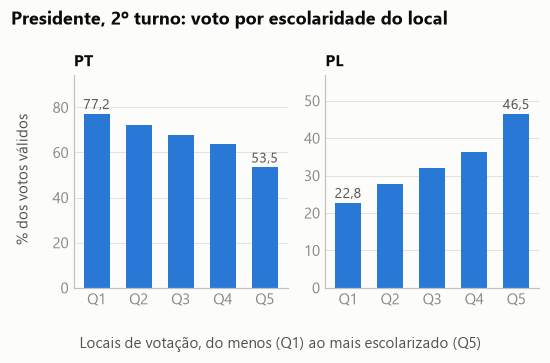

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"28,0","26,6","24,2","25,0","22,9","25,1"
PP,"13,1","14,5","15,4","17,7","24,1","17,0"
PSD,"16,1","14,4","14,8","13,5","12,1","14,1"
REPUBLICANOS,"13,8","13,6","13,6","11,8","9,5","12,5"
SOLIDARIEDADE,"9,4","10,3","9,8","8,9","6,1","8,9"
UNIÃO,"5,9","5,7","5,7","5,8","6,0","5,8"
PL,"2,5","3,0","3,8","3,9","4,7","3,6"
PV,"3,5","4,0","3,0","3,0","2,3","3,1"
Outros,"7,7","8,0","9,6","10,5","12,4","9,7"


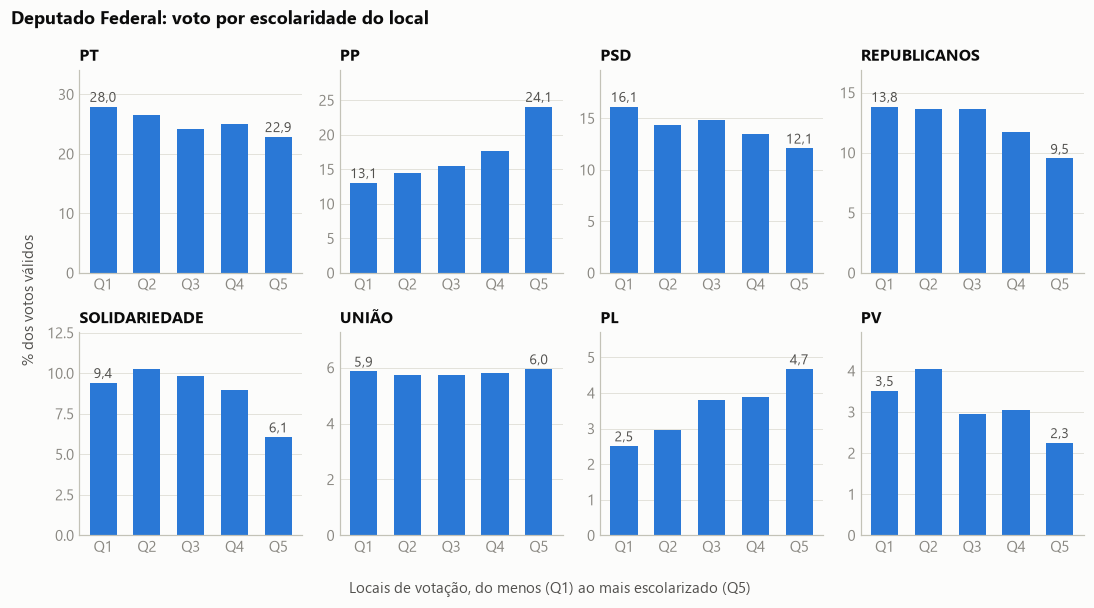

In [9]:
def voto_por_quintil(df: pd.DataFrame, disputa: str, variavel: str) -> pd.DataFrame:
    """% dos votos válidos de cada partido em cada quinto das unidades de `df`,
    ordenadas por `variavel`. Linhas = partidos; última coluna = o município."""
    votos = votos_por_partido(df, disputa)
    quintil = pd.qcut(df[variavel], 5, labels=QUINTIS)
    soma = votos.groupby(quintil, observed=True).sum()
    tabela = (100 * soma.div(soma.sum(axis=1), axis=0)).T
    tabela["Total"] = 100 * votos.sum() / votos.sum().sum()
    return tabela.rename_axis(index="partido", columns=None)


def grafico_quintis(tabela: pd.DataFrame, titulo: str, rotulo_x: str) -> None:
    """Um painel por partido; a escala vertical é a de cada partido, a partir de zero."""
    partidos = [p for p in tabela.index if p != "Outros"]
    ncol = min(4, len(partidos))
    nlin = -(-len(partidos) // ncol)
    fig, eixos = plt.subplots(nlin, ncol, figsize=(2.5 * ncol, 2.3 * nlin + 0.9), squeeze=False)
    for eixo, partido in zip(eixos.flat, partidos):
        valores = tabela.loc[partido, QUINTIS]
        eixo.bar(QUINTIS, valores, width=0.62, color=COR)
        eixo.set_title(partido)
        eixo.set_ylim(0, valores.max() * 1.22)
        eixo.grid(axis="x", visible=False)
        eixo.tick_params(length=0)
        for i in (0, 4):  # rótulo só nos extremos
            eixo.annotate(numero(valores.iloc[i]), (i, valores.iloc[i]), xytext=(0, 3),
                          textcoords="offset points", ha="center", fontsize=9, color=COR_TINTA_2)
    for eixo in eixos.flat[len(partidos):]:
        eixo.set_visible(False)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(rotulo_x, fontsize=9.5, color=COR_TINTA_2)
    fig.supylabel("% dos votos válidos", fontsize=9.5, color=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


faixas = local.groupby(pd.qcut(local["pc_esc_superior"], 5, labels=QUINTIS), observed=True)["pc_esc_superior"].agg(["min", "max"])
print("% com superior completo em cada grupo de locais:")
print("  " + " | ".join(f"{q}: {numero(100 * r['min'])} a {numero(100 * r['max'])}" for q, r in faixas.iterrows()))

for disputa, nome in DISPUTAS.items():
    tabela = voto_por_quintil(local, disputa, "pc_esc_superior")
    display(tabela.style.format(precision=1, decimal=",").set_caption(f"{nome}: % dos votos válidos por grupo de locais"))
    grafico_quintis(tabela, f"{nome}: voto por escolaridade do local",
                    "Locais de votação, do menos (Q1) ao mais escolarizado (Q5)")

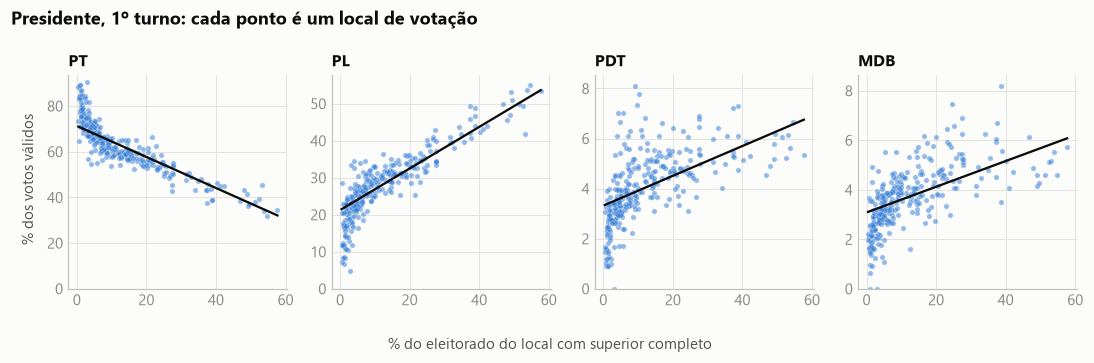

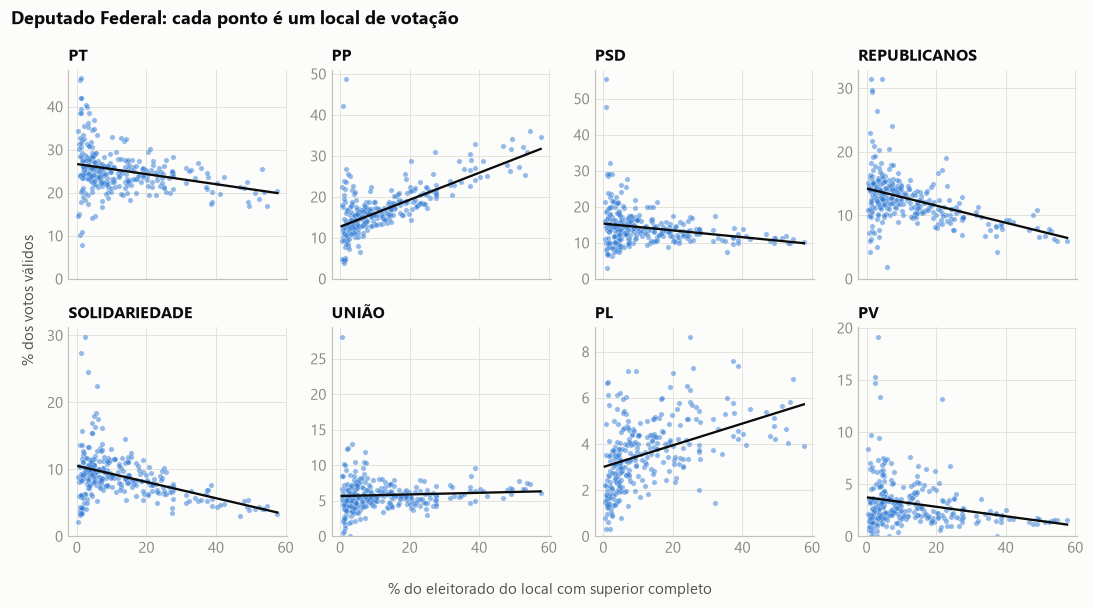

In [10]:
def grafico_dispersao(df: pd.DataFrame, disputa: str, x: pd.Series, rotulo_x: str, titulo: str, log_x: bool = False) -> None:
    """Um painel por partido: cada ponto é uma unidade de `df`; a reta é o ajuste
    ponderado pelos votos válidos."""
    votos = votos_por_partido(df, disputa)
    validos = votos.sum(axis=1)
    partidos = [p for p in votos.columns if p != "Outros"]
    ncol = min(4, len(partidos))
    nlin = -(-len(partidos) // ncol)
    fig, eixos = plt.subplots(nlin, ncol, figsize=(2.5 * ncol, 2.3 * nlin + 0.9), squeeze=False, sharex=True)
    for eixo, partido in zip(eixos.flat, partidos):
        y = 100 * votos[partido] / validos
        ok = x.notna() & y.notna() & (validos > 0)
        eixo.scatter(x[ok], y[ok], s=12, color=COR, alpha=0.5, edgecolor=COR_FUNDO, linewidth=0.3)
        xs = np.log10(x[ok]) if log_x else x[ok]
        inclinacao, intercepto = np.polyfit(xs, y[ok], 1, w=np.sqrt(validos[ok]))
        pontas = np.array([xs.min(), xs.max()])
        eixo.plot(10 ** pontas if log_x else pontas, intercepto + inclinacao * pontas, color=COR_TINTA, linewidth=1.5)
        if log_x:
            eixo.set_xscale("log")
            marcas = [m for m in (1000, 2000, 5000, 10000, 20000) if x[ok].min() <= m <= x[ok].max()]
            eixo.set_xticks(marcas, [f"{m // 1000} mil" for m in marcas])
            eixo.minorticks_off()
        eixo.set_title(partido)
        eixo.set_ylim(bottom=0)
        eixo.tick_params(length=0)
    for eixo in eixos.flat[len(partidos):]:
        eixo.set_visible(False)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(rotulo_x, fontsize=9.5, color=COR_TINTA_2)
    fig.supylabel("% dos votos válidos", fontsize=9.5, color=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


for disputa in [d for d in ("pres_t1", "depfed_t1") if d in DISPUTAS]:
    grafico_dispersao(local, disputa, 100 * local["pc_esc_superior"],
                      "% do eleitorado do local com superior completo",
                      f"{DISPUTAS[disputa]}: cada ponto é um local de votação")

## Voto × renda, por setor censitário

Aqui o voto é o **estimado** por setor. Os setores são ordenados pela renda média
do responsável pelo domicílio (Q1 = setores mais pobres, Q5 = mais ricos).

Renda média do responsável (R$) em cada grupo de setores:
  Q1: 706 a 1.294 | Q2: 1.294 a 1.604 | Q3: 1.605 a 2.167 | Q4: 2.167 a 3.350 | Q5: 3.364 a 19.864


,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"71,0","68,5","65,5","61,0","52,0","62,4"
PL,"22,0","23,7","26,0","29,4","37,3","28,6"
PDT,"3,1","3,5","3,9","4,4","5,0","4,1"
MDB,"2,8","3,2","3,5","4,1","4,5","3,8"
Outros,"1,0","1,1","1,1","1,1","1,2","1,1"


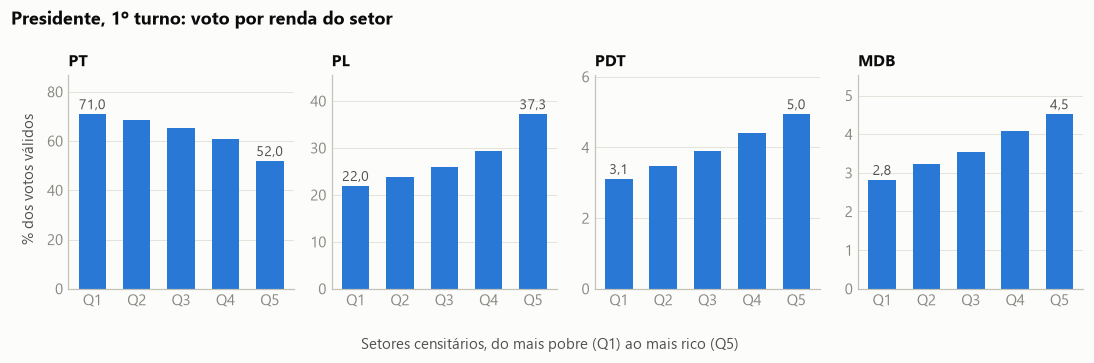

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"74,0","71,9","69,4","65,4","56,9","66,5"
PL,"26,0","28,1","30,6","34,6","43,1","33,5"


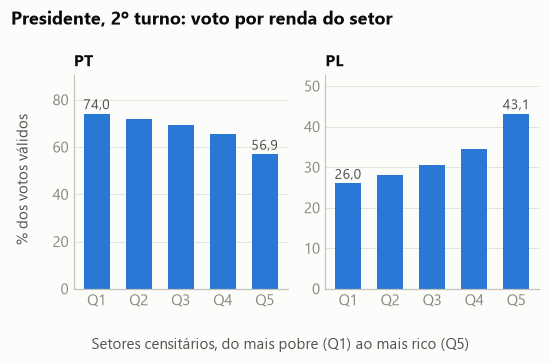

,Q1,Q2,Q3,Q4,Q5,Total
partido,,,,,,
PT,"27,9","25,8","25,4","25,0","23,2","25,1"
PP,"13,6","14,7","15,2","16,9","22,4","17,0"
PSD,"14,5","15,6","14,5","13,9","12,7","14,1"
REPUBLICANOS,"13,5","13,5","13,5","12,2","10,4","12,5"
SOLIDARIEDADE,"9,1","9,8","9,8","9,4","6,9","8,9"
UNIÃO,"6,2","5,7","5,7","5,7","5,9","5,8"
PL,"2,9","3,0","3,5","3,8","4,4","3,6"
PV,"3,9","3,3","3,4","3,1","2,5","3,1"
Outros,"8,3","8,4","9,2","9,9","11,8","9,7"


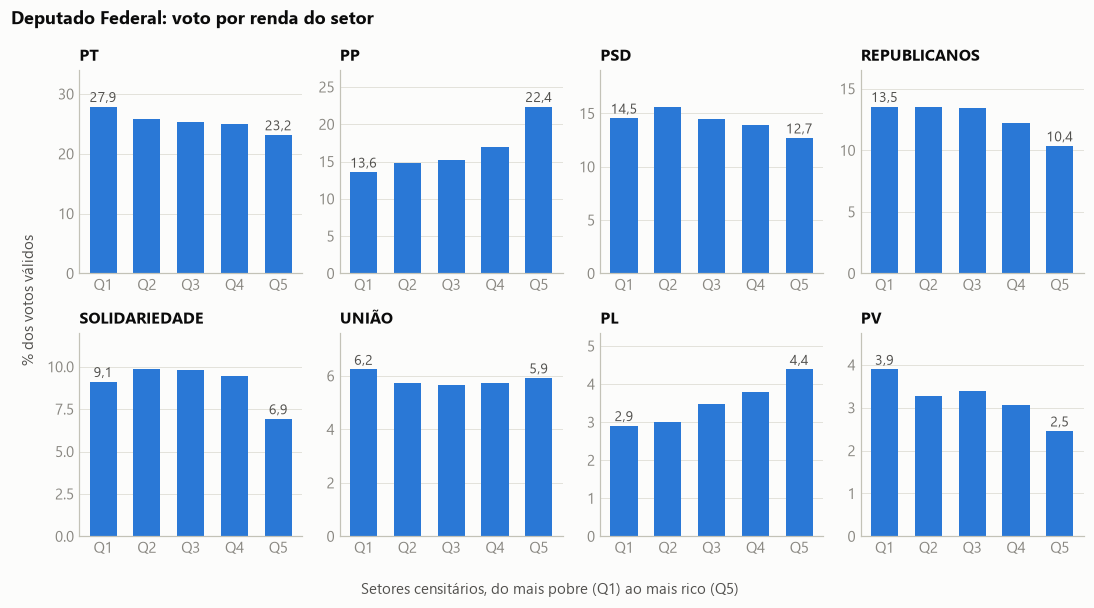

In [11]:
faixas = setor.groupby(pd.qcut(setor["renda_media_resp"], 5, labels=QUINTIS), observed=True)["renda_media_resp"].agg(["min", "max"])
print("Renda média do responsável (R$) em cada grupo de setores:")
print("  " + " | ".join(f"{q}: {numero(r['min'], 0)} a {numero(r['max'], 0)}" for q, r in faixas.iterrows()))

for disputa, nome in DISPUTAS.items():
    tabela = voto_por_quintil(setor, disputa, "renda_media_resp")
    display(tabela.style.format(precision=1, decimal=",").set_caption(f"{nome}: % dos votos válidos por grupo de setores"))
    grafico_quintis(tabela, f"{nome}: voto por renda do setor",
                    "Setores censitários, do mais pobre (Q1) ao mais rico (Q5)")

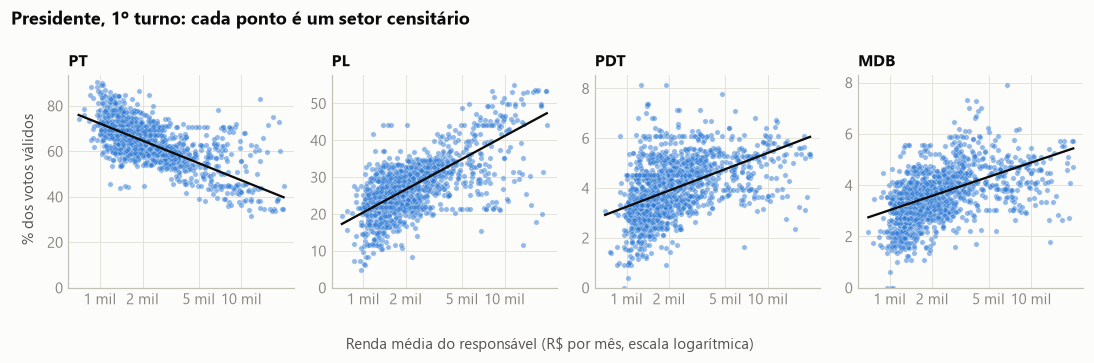

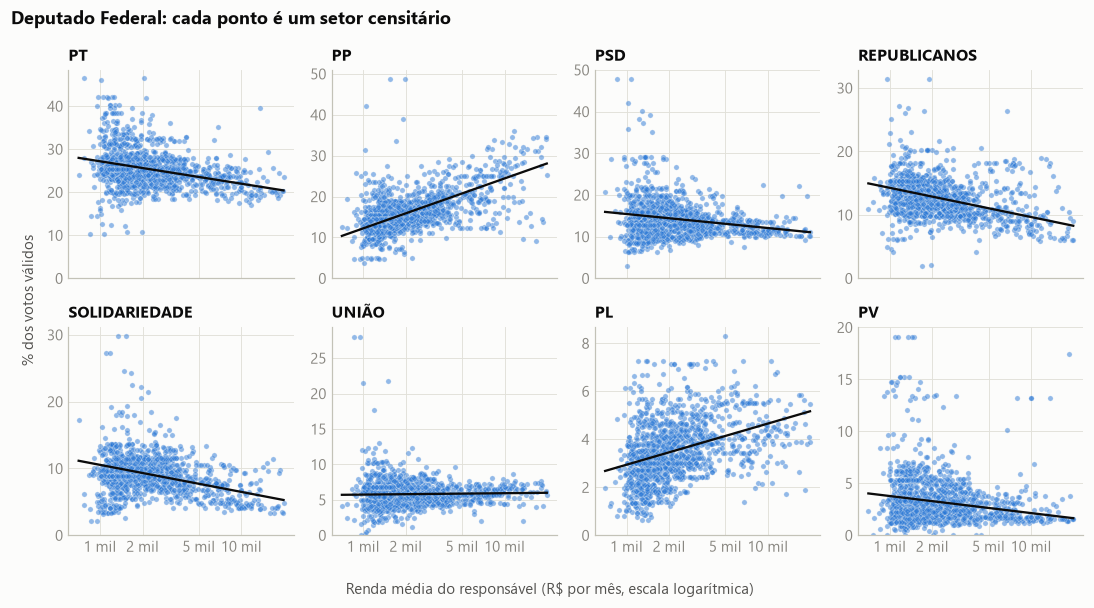

In [12]:
for disputa in [d for d in ("pres_t1", "depfed_t1") if d in DISPUTAS]:
    grafico_dispersao(setor, disputa, setor["renda_media_resp"],
                      "Renda média do responsável (R$ por mês, escala logarítmica)",
                      f"{DISPUTAS[disputa]}: cada ponto é um setor censitário", log_x=True)

## Regressão

Uma regressão por partido, ponderada pelos votos válidos de cada unidade. A
variável explicada é o percentual dos votos válidos do partido. Os preditores
são padronizados: o coeficiente é a variação, **em pontos percentuais, para um
desvio-padrão a mais** do preditor, mantidos os outros.

- **Por local** (tudo observado): superior completo, idade média e % de mulheres.
- **Por setor** (voto e cadastro estimados, renda observada): os mesmos mais o
  logaritmo da renda; erro padrão agrupado pelo local dominante do setor.

Os gráficos por quintil acima mostram a relação bruta de cada variável com o
voto; a regressão mostra o que sobra de cada uma quando as outras entram junto.
Escolaridade e renda andam juntas no território (ver a correlação abaixo), então
os dois coeficientes do modelo por setor dividem um efeito que em boa parte é
comum. Vale olhar o sinal e a ordem de grandeza, não o valor exato.

In [13]:
ROTULOS = {
    "pc_esc_superior": "Superior completo",
    "log_renda": "Renda (log)",
    "log_renda_area": "Renda da área do local (log)",
    "idade_media": "Idade média",
    "pc_feminino": "% de mulheres",
}
PREDITORES_LOCAL = ["pc_esc_superior", "idade_media", "pc_feminino"]
PREDITORES_SETOR = ["pc_esc_superior", "log_renda", "idade_media", "pc_feminino"]


def regressao(df: pd.DataFrame, disputa: str, preditores: list[str], grupo: str | None = None) -> pd.DataFrame:
    """Uma regressão ponderada por partido. Sem `grupo`, erro padrão robusto (HC1);
    com `grupo`, agrupado por essa coluna."""
    votos = votos_por_partido(df, disputa)
    validos = votos.sum(axis=1)
    linhas = []
    for partido in votos.columns.drop("Outros", errors="ignore"):
        base = df[preditores].assign(y=100 * votos[partido] / validos, peso=validos)
        if grupo:
            base["grupo"] = df[grupo]
        base = base.replace([np.inf, -np.inf], np.nan).dropna()
        base = base.loc[base["peso"] > 0]
        X = sm.add_constant((base[preditores] - base[preditores].mean()) / base[preditores].std())
        modelo = sm.WLS(base["y"], X, weights=base["peso"])
        if grupo:
            ajuste = modelo.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(base["grupo"])[0]})
        else:
            ajuste = modelo.fit(cov_type="HC1")
        ic = ajuste.conf_int()
        for preditor in preditores:
            linhas.append({
                "partido": partido, "preditor": preditor, "coef": ajuste.params[preditor],
                "ic_min": ic.loc[preditor, 0], "ic_max": ic.loc[preditor, 1],
                "p_valor": ajuste.pvalues[preditor], "r2": ajuste.rsquared, "n": int(ajuste.nobs),
            })
    return pd.DataFrame(linhas)


def tabela_coeficientes(coefs: pd.DataFrame) -> pd.DataFrame:
    """Coeficientes (p.p. por desvio-padrão) com o intervalo de 95%, mais R² e n."""
    texto = coefs.apply(lambda r: f"{numero(r['coef'])} [{numero(r['ic_min'])}; {numero(r['ic_max'])}]", axis=1)
    larga = coefs.assign(texto=texto).pivot(index="partido", columns="preditor", values="texto")
    larga = larga[coefs["preditor"].unique()].rename(columns=ROTULOS).loc[coefs["partido"].unique()]
    resumo = coefs.groupby("partido")[["r2", "n"]].first()
    larga = larga.assign(R2=resumo["r2"].map(lambda v: numero(v, 2)), n=resumo["n"])
    return larga.rename_axis(index="partido", columns=None)


def grafico_coeficientes(coefs: pd.DataFrame, preditores: list[str], titulo: str) -> None:
    """Coeficiente e intervalo de 95% por partido, um painel por preditor."""
    partidos = list(coefs["partido"].unique())[::-1]
    fig, eixos = plt.subplots(1, len(preditores), figsize=(3.6 * len(preditores) + 1.2, 0.36 * len(partidos) + 1.7),
                              sharey=True, squeeze=False)
    for eixo, preditor in zip(eixos.flat, preditores):
        d = coefs.loc[coefs["preditor"] == preditor].set_index("partido").loc[partidos]
        eixo.axvline(0, color=COR_EIXO, linewidth=1)
        eixo.hlines(d.index, d["ic_min"], d["ic_max"], color=COR, linewidth=2)
        eixo.scatter(d["coef"], d.index, s=44, color=COR, edgecolor=COR_FUNDO, linewidth=1.2, zorder=3)
        eixo.set_title(ROTULOS[preditor])
        eixo.grid(axis="y", visible=False)
        eixo.tick_params(length=0)
        eixo.tick_params(axis="y", labelcolor=COR_TINTA_2)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel("Pontos percentuais dos votos válidos para +1 desvio-padrão (ponto) e intervalo de 95% (traço)",
                  fontsize=9.5, color=COR_TINTA_2)
    fig.tight_layout()
    plt.show()


desvios = pd.DataFrame({
    "local": local[PREDITORES_LOCAL + ["log_renda_area"]].std(),
    "setor": setor[PREDITORES_SETOR].std(),
}).rename(index=ROTULOS).round(3)
print("Desvio-padrão de cada preditor (superior e mulheres em fração; renda em log):")
display(desvios)
print("Correlação entre superior completo e log da renda, por setor:",
      numero(setor["pc_esc_superior"].corr(setor["log_renda"]), 2))

Desvio-padrão de cada preditor (superior e mulheres em fração; renda em log):


,local,setor
Idade média,5.476,4.988
Renda (log),NaN,0.638
Renda da área do local (log),0.571,NaN
Superior completo,0.123,0.114
% de mulheres,0.024,0.018


Correlação entre superior completo e log da renda, por setor: 0,72


### Por local de votação (observado)

,Superior completo,Idade média,% de mulheres,R2,n
partido,,,,,
PT,"-8,3 [-9,1; -7,5]","0,6 [-0,0; 1,2]","-1,2 [-1,9; -0,5]","0,82",296
PL,"7,0 [6,3; 7,6]","-0,6 [-1,1; -0,1]","0,7 [0,1; 1,3]","0,83",296
PDT,"0,8 [0,7; 0,9]","-0,3 [-0,5; -0,2]","0,2 [0,0; 0,3]","0,49",296
MDB,"0,5 [0,4; 0,6]","0,4 [0,2; 0,5]","0,3 [0,2; 0,4]","0,52",296


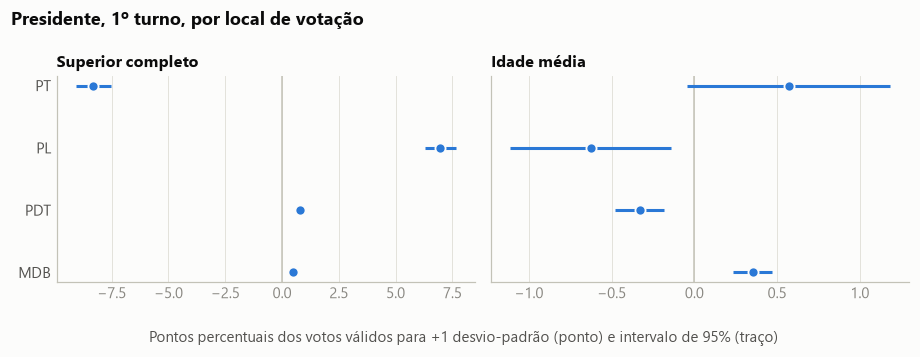

,Superior completo,Idade média,% de mulheres,R2,n
partido,,,,,
PT,"-7,9 [-8,6; -7,1]","0,9 [0,3; 1,5]","-0,9 [-1,6; -0,3]","0,82",296
PL,"7,9 [7,1; 8,6]","-0,9 [-1,5; -0,3]","0,9 [0,3; 1,6]","0,82",296


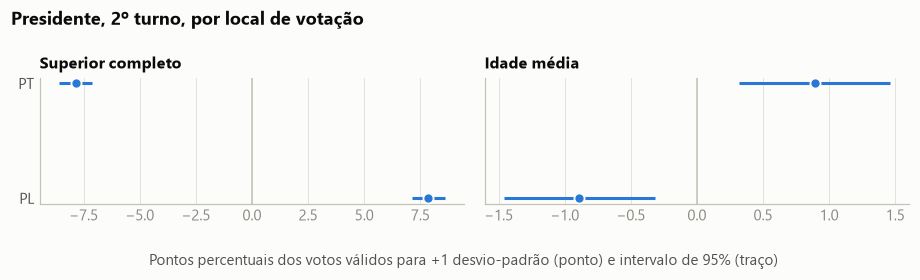

,Superior completo,Idade média,% de mulheres,R2,n
partido,,,,,
PT,"-1,6 [-2,1; -1,1]","0,5 [-0,1; 1,2]","-0,2 [-0,8; 0,4]","0,14",296
PP,"3,9 [3,4; 4,4]","0,6 [0,2; 1,0]","-0,1 [-0,6; 0,4]","0,66",296
PSD,"-1,1 [-1,4; -0,8]","0,2 [-0,3; 0,8]","-0,7 [-1,3; -0,0]","0,10",296
REPUBLICANOS,"-1,6 [-1,8; -1,4]","-0,3 [-0,6; 0,0]","0,1 [-0,3; 0,5]","0,36",296
SOLIDARIEDADE,"-1,5 [-1,7; -1,3]","-0,0 [-0,3; 0,3]","0,2 [-0,2; 0,6]","0,29",296
UNIÃO,"0,3 [0,1; 0,4]","-0,4 [-0,7; -0,2]","0,0 [-0,2; 0,2]","0,04",296
PL,"0,5 [0,3; 0,7]","0,1 [-0,1; 0,3]","0,2 [0,1; 0,4]","0,26",296
PV,"-0,5 [-0,7; -0,3]","-0,1 [-0,5; 0,3]","0,1 [-0,2; 0,4]","0,08",296


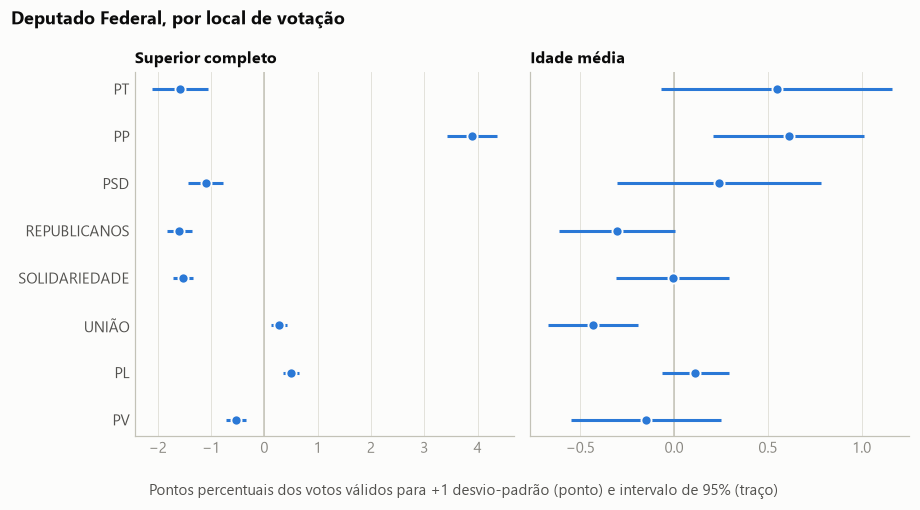

In [14]:
coefs_local = {d: regressao(local, d, PREDITORES_LOCAL) for d in DISPUTAS}
for disputa, nome in DISPUTAS.items():
    display(tabela_coeficientes(coefs_local[disputa]).style.set_caption(f"{nome}, por local"))
    grafico_coeficientes(coefs_local[disputa], ["pc_esc_superior", "idade_media"], f"{nome}, por local de votação")

### Por setor censitário (voto estimado, renda observada)

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PT,"-7,2 [-8,2; -6,3]","-0,4 [-1,1; 0,2]","0,3 [-0,3; 1,0]","-1,3 [-1,9; -0,7]","0,84",1379
PL,"6,1 [5,2; 6,9]","0,4 [-0,2; 1,0]","-0,5 [-1,0; -0,0]","0,9 [0,4; 1,3]","0,85",1379
PDT,"0,7 [0,6; 0,8]","0,0 [-0,1; 0,1]","-0,2 [-0,4; -0,1]","0,2 [0,1; 0,3]","0,53",1379
MDB,"0,4 [0,3; 0,5]","-0,0 [-0,1; 0,1]","0,4 [0,3; 0,5]","0,3 [0,2; 0,4]","0,57",1379


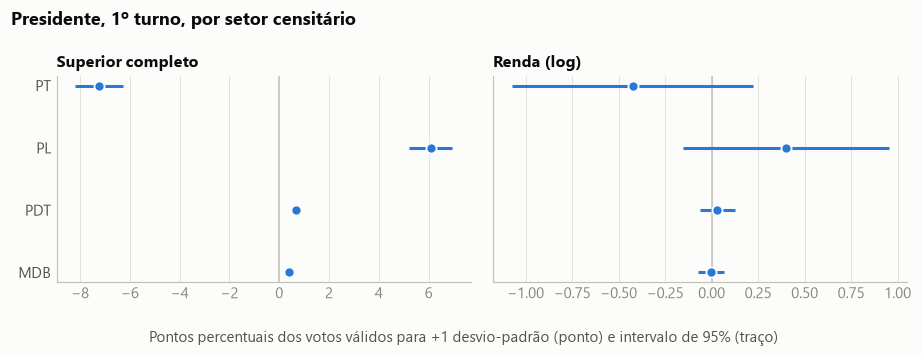

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PT,"-6,9 [-7,8; -5,9]","-0,4 [-1,0; 0,2]","0,7 [0,1; 1,3]","-1,1 [-1,7; -0,6]","0,85",1379
PL,"6,9 [5,9; 7,8]","0,4 [-0,2; 1,0]","-0,7 [-1,3; -0,1]","1,1 [0,6; 1,7]","0,85",1379


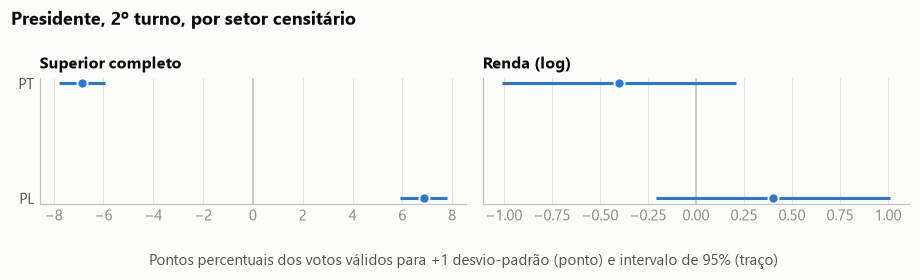

,Superior completo,Renda (log),Idade média,% de mulheres,R2,n
partido,,,,,,
PT,"-0,9 [-1,5; -0,4]","-0,7 [-1,1; -0,3]","0,4 [-0,3; 1,0]","-0,1 [-0,5; 0,4]","0,17",1379
PP,"3,5 [3,0; 4,0]","0,2 [-0,1; 0,5]","0,6 [0,1; 1,0]","-0,1 [-0,5; 0,3]","0,71",1379
PSD,"-1,1 [-1,5; -0,7]","0,1 [-0,3; 0,5]","0,3 [-0,2; 0,9]","-0,8 [-1,4; -0,1]","0,13",1379
REPUBLICANOS,"-1,6 [-1,8; -1,3]","0,2 [-0,1; 0,5]","-0,4 [-0,7; -0,1]","0,1 [-0,2; 0,4]","0,40",1379
SOLIDARIEDADE,"-1,6 [-1,8; -1,4]","0,2 [0,0; 0,5]","0,1 [-0,2; 0,4]","0,2 [-0,2; 0,5]","0,32",1379
UNIÃO,"0,4 [0,3; 0,6]","-0,2 [-0,4; 0,0]","-0,5 [-0,7; -0,2]","-0,0 [-0,2; 0,2]","0,05",1379
PL,"0,4 [0,2; 0,6]","0,0 [-0,1; 0,2]","0,2 [0,0; 0,3]","0,2 [0,1; 0,4]","0,30",1379
PV,"-0,5 [-0,7; -0,3]","0,0 [-0,2; 0,3]","-0,2 [-0,5; 0,2]","0,1 [-0,2; 0,3]","0,09",1379


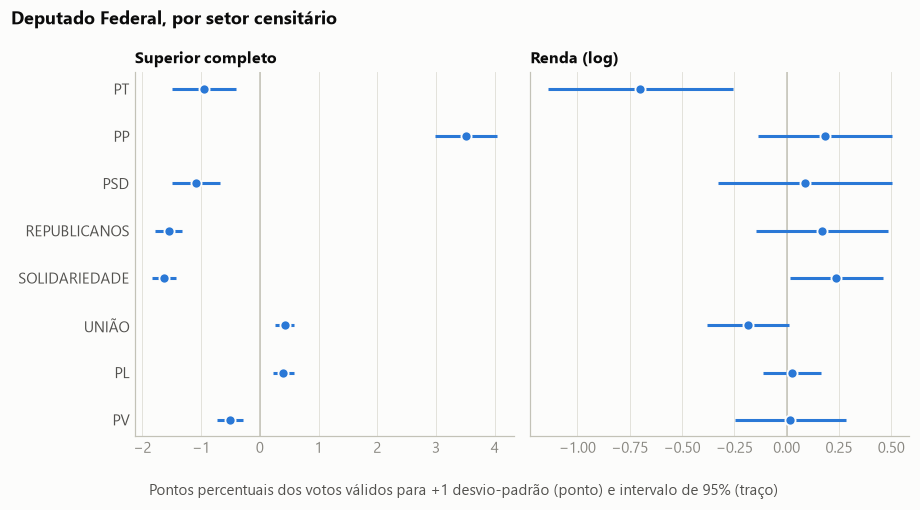

In [15]:
coefs_setor = {d: regressao(setor, d, PREDITORES_SETOR, grupo="id_local_dominante") for d in DISPUTAS}
for disputa, nome in DISPUTAS.items():
    display(tabela_coeficientes(coefs_setor[disputa]).style.set_caption(f"{nome}, por setor"))
    grafico_coeficientes(coefs_setor[disputa], ["pc_esc_superior", "log_renda"], f"{nome}, por setor censitário")

### Cada faixa de escolaridade, com p-valor

As quatro faixas somam 100% do eleitorado, então não entram juntas no mesmo modelo
(colinearidade perfeita). Cada faixa entra **sozinha**, com os controles do modelo
(por local: idade média e % de mulheres; por setor: também a renda), e o erro padrão
do modelo por setor segue agrupado pelo local dominante. O coeficiente é a variação,
em pontos percentuais do voto, para +1 desvio-padrão do peso daquela faixa.

Como são muitos testes (partidos × faixas), mostro também o **p ajustado de Holm**,
calculado dentro de cada disputa e de cada nível. Asteriscos no p ajustado: `***` <
0,001, `**` < 0,01, `*` < 0,05.

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"9,7*** (p < 0,001)","11,6*** (p < 0,001)","-3,3*** (p < 0,001)","-8,3*** (p < 0,001)"
PL,"-7,8*** (p < 0,001)","-9,6*** (p < 0,001)","2,1*** (p < 0,001)","7,0*** (p < 0,001)"
PDT,"-1,1*** (p < 0,001)","-1,2*** (p < 0,001)","0,6*** (p < 0,001)","0,8*** (p < 0,001)"
MDB,"-0,7*** (p < 0,001)","-0,7*** (p < 0,001)","0,5*** (p < 0,001)","0,5*** (p < 0,001)"


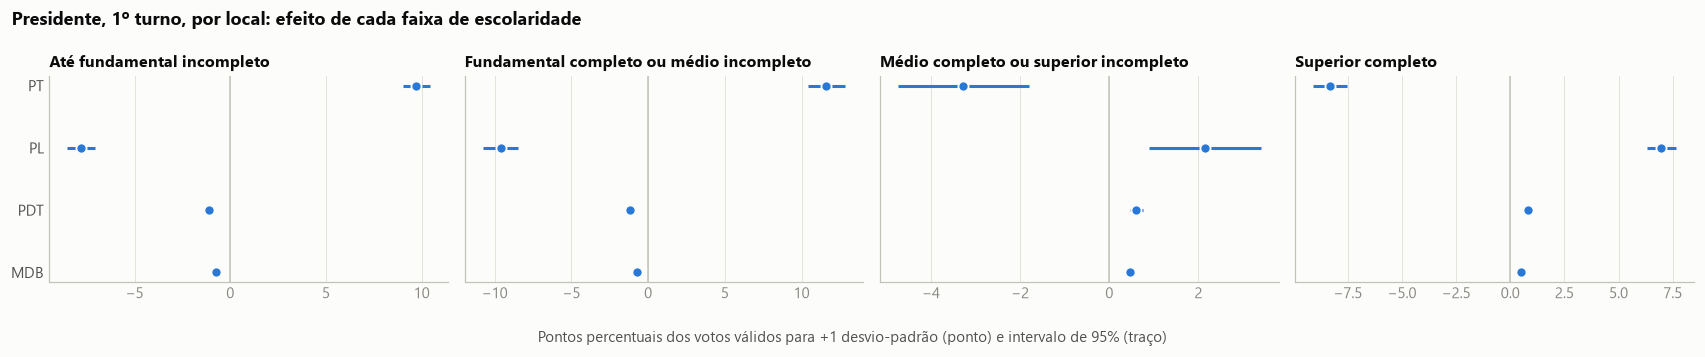

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"8,9*** (p < 0,001)","10,8*** (p < 0,001)","-2,7*** (p < 0,001)","-7,9*** (p < 0,001)"
PL,"-8,9*** (p < 0,001)","-10,8*** (p < 0,001)","2,7*** (p < 0,001)","7,9*** (p < 0,001)"


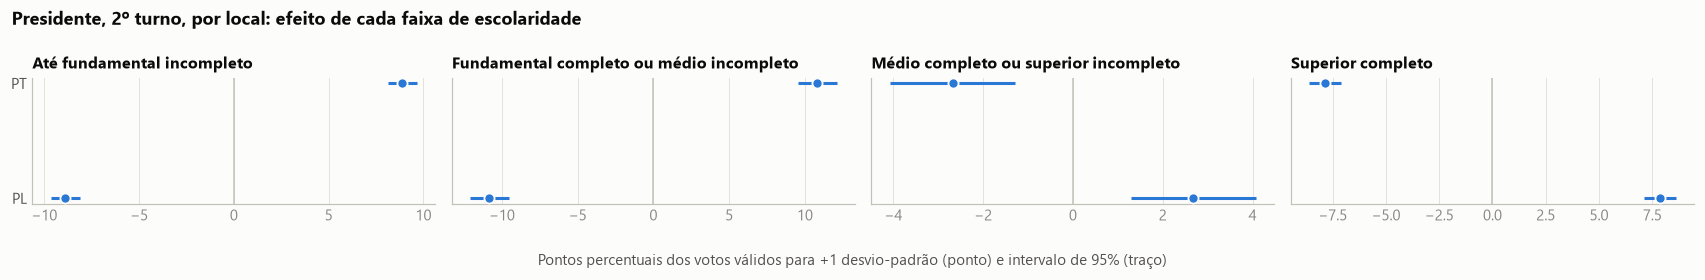

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"1,6*** (p < 0,001)","2,3*** (p < 0,001)","-0,3 (p 0,380)","-1,6*** (p < 0,001)"
PP,"-3,5*** (p < 0,001)","-5,4*** (p < 0,001)","-0,1 (p 0,840)","3,9*** (p < 0,001)"
PSD,"1,3** (p < 0,001)","1,4*** (p < 0,001)","-0,3 (p 0,317)","-1,1*** (p < 0,001)"
REPUBLICANOS,"1,6*** (p < 0,001)","2,3*** (p < 0,001)","-0,3 (p 0,204)","-1,6*** (p < 0,001)"
SOLIDARIEDADE,"1,2*** (p < 0,001)","2,1*** (p < 0,001)","0,2 (p 0,256)","-1,5*** (p < 0,001)"
UNIÃO,"-0,2 (p 0,231)","-0,3 (p 0,062)","-0,1 (p 0,404)","0,3** (p < 0,001)"
PL,"-0,7*** (p < 0,001)","-0,7*** (p < 0,001)","0,4*** (p < 0,001)","0,5*** (p < 0,001)"
PV,"0,5** (p < 0,001)","0,7** (p < 0,001)","-0,1 (p 0,498)","-0,5*** (p < 0,001)"


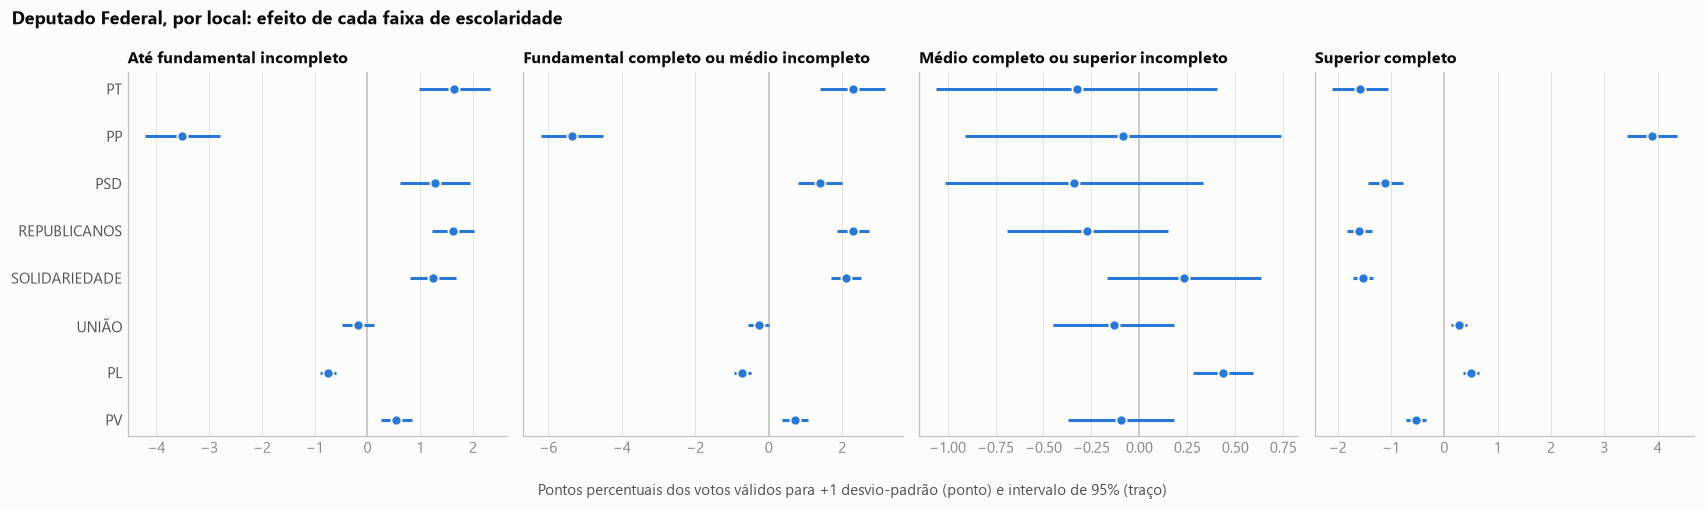

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"7,3*** (p < 0,001)","8,7*** (p < 0,001)","-2,7*** (p < 0,001)","-7,2*** (p < 0,001)"
PL,"-5,6*** (p < 0,001)","-7,1*** (p < 0,001)","1,7*** (p < 0,001)","6,1*** (p < 0,001)"
PDT,"-1,0*** (p < 0,001)","-1,0*** (p < 0,001)","0,5*** (p < 0,001)","0,7*** (p < 0,001)"
MDB,"-0,7*** (p < 0,001)","-0,6*** (p < 0,001)","0,4*** (p < 0,001)","0,4*** (p < 0,001)"


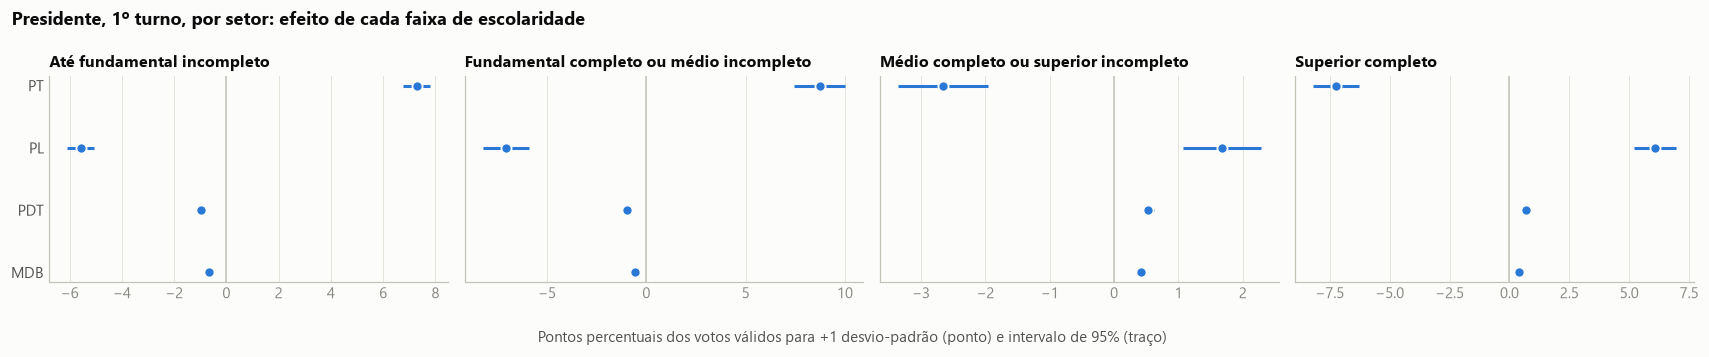

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"6,5*** (p < 0,001)","8,0*** (p < 0,001)","-2,1*** (p < 0,001)","-6,9*** (p < 0,001)"
PL,"-6,5*** (p < 0,001)","-8,0*** (p < 0,001)","2,1*** (p < 0,001)","6,9*** (p < 0,001)"


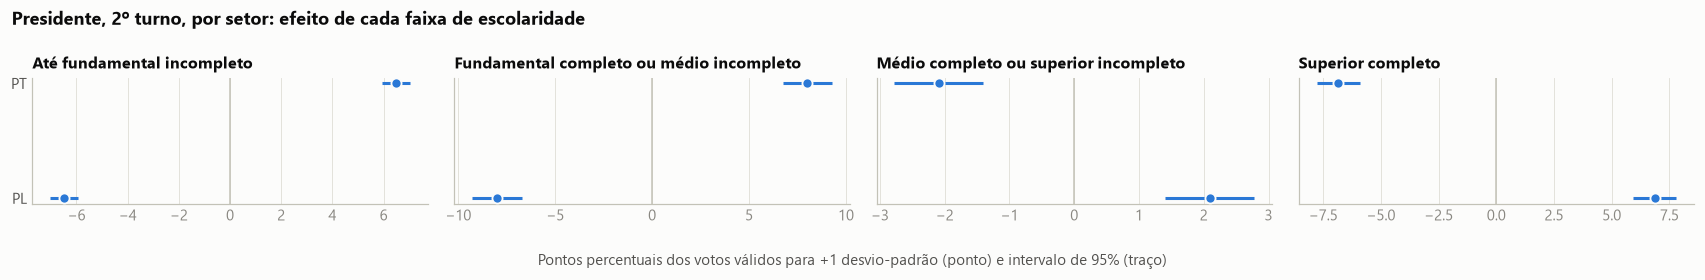

,Até fundamental incompleto,Fundamental completo ou médio incompleto,Médio completo ou superior incompleto,Superior completo
partido,,,,
PT,"0,9* (p 0,004)","1,3 (p 0,007)","-0,3 (p 0,311)","-0,9* (p < 0,001)"
PP,"-1,9*** (p < 0,001)","-4,1*** (p < 0,001)","-0,3 (p 0,263)","3,5*** (p < 0,001)"
PSD,"1,0* (p 0,003)","1,0 (p 0,036)","-0,2 (p 0,385)","-1,1*** (p < 0,001)"
REPUBLICANOS,"1,1*** (p < 0,001)","1,9*** (p < 0,001)","-0,1 (p 0,370)","-1,6*** (p < 0,001)"
SOLIDARIEDADE,"0,7** (p < 0,001)","2,0*** (p < 0,001)","0,3 (p 0,065)","-1,6*** (p < 0,001)"
UNIÃO,"-0,2 (p 0,256)","-0,3 (p 0,029)","-0,1 (p 0,381)","0,4*** (p < 0,001)"
PL,"-0,6*** (p < 0,001)","-0,5** (p < 0,001)","0,4*** (p < 0,001)","0,4*** (p < 0,001)"
PV,"0,4 (p 0,011)","0,6* (p 0,003)","-0,1 (p 0,530)","-0,5*** (p < 0,001)"


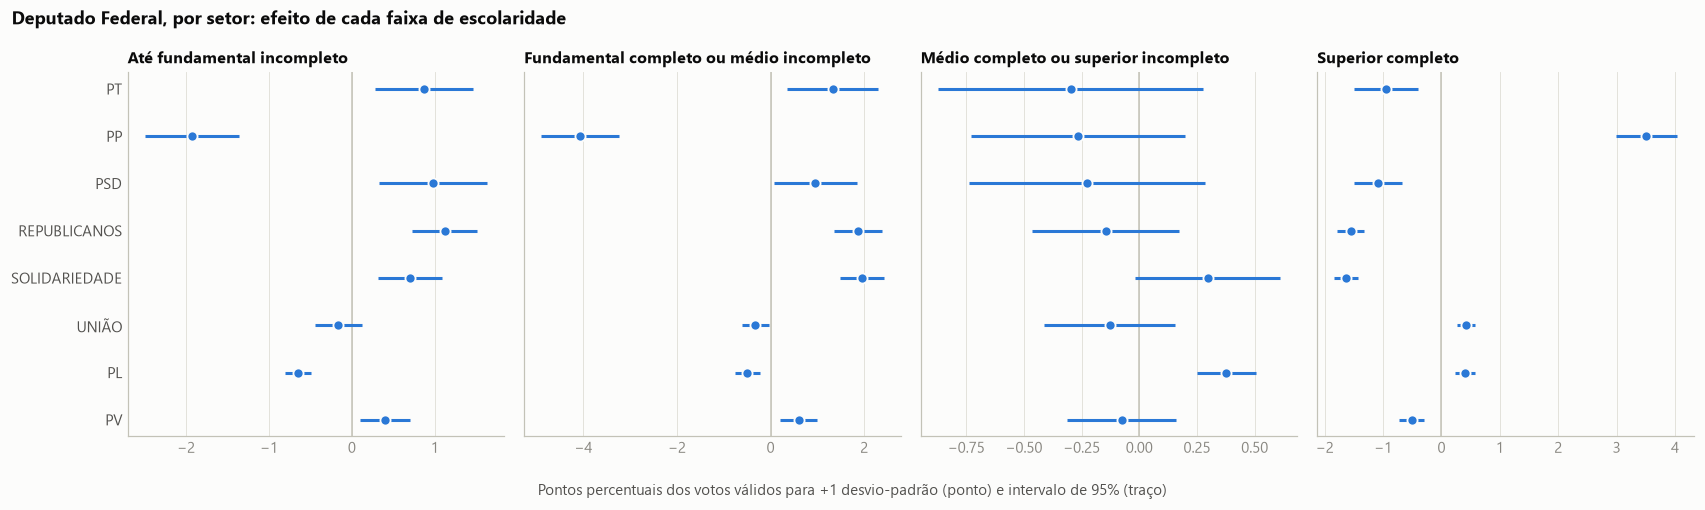

significativos (Holm < 0,05)  \
nível     disputa   faixa                                                                    
por local pres_t1   Até fundamental incompleto                                           4   
                    Fundamental completo ou médio incompleto                             4   
                    Médio completo ou superior incompleto                                4   
                    Superior completo                                                    4   
          pres_t2   Até fundamental incompleto                                           2   
                    Fundamental completo ou médio incompleto                             2   
                    Médio completo ou superior incompleto                                2   
                    Superior completo                                                    2   
          depfed_t1 Até fundamental incompleto                                           7   
                    Fundamental completo ou médio incompleto                             7   
                    Médio completo ou superior incompleto                                1   
                    Superior completo                                                    8   
por setor pres_t1   Até fundamental incompleto                                           4   
                    Fundamental completo ou médio incompleto                             4   
                    Médio completo ou superior incompleto                                4   
                    Superior completo                                                    4   
          pres_t2   Até fundamental incompleto                                           2   
                    Fundamental completo ou médio incompleto                             2   
                    Médio completo ou superior incompleto                                2   
                    Superior completo                                                    2   
          depfed_t1 Até fundamental incompleto                                           6   
                    Fundamental completo ou médio incompleto                             5   
                    Médio completo ou superior incompleto                                1   
                    Superior completo                                                    8   

                                                              testes  
nível     disputa   faixa                                             
por local pres_t1   Até fundamental incompleto                     4  
                    Fundamental completo ou médio incompleto       4  
                    Médio completo ou superior incompleto          4  
                    Superior completo                              4  
          pres_t2   Até fundamental incompleto                     2  
                    Fundamental completo ou médio incompleto       2  
                    Médio completo ou superior incompleto          2  
                    Superior completo                              2  
          depfed_t1 Até fundamental incompleto                     8  
                    Fundamental completo ou médio incompleto       8  
                    Médio completo ou superior incompleto          8  
                    Superior completo                              8  
por setor pres_t1   Até fundamental incompleto                     4  
                    Fundamental completo ou médio incompleto       4  
                    Médio completo ou superior incompleto          4  
                    Superior completo                              4  
          pres_t2   Até fundamental incompleto                     2  
                    Fundamental completo ou médio incompleto       2  
                    Médio completo ou superior incompleto          2  
                    Superior completo                              2  
          depfed_t1 Até fundamental incompleto         

In [16]:
from statsmodels.stats.multitest import multipletests

FAIXAS_ESC = {
    "pc_esc_ate_fund_incompleto": "Até fundamental incompleto",
    "pc_esc_fund_completo": "Fundamental completo ou médio incompleto",
    "pc_esc_medio_completo": "Médio completo ou superior incompleto",
    "pc_esc_superior": "Superior completo",
}
ROTULOS.update(FAIXAS_ESC)


def estrelas(p: float) -> str:
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def regressao_por_faixa(df: pd.DataFrame, disputa: str, controles: list[str], grupo: str | None = None) -> pd.DataFrame:
    """Uma regressão por partido e por faixa de escolaridade (cada faixa sozinha, com os controles)."""
    partes = []
    for faixa in FAIXAS_ESC:
        r = regressao(df, disputa, [faixa, *controles], grupo=grupo).query("preditor == @faixa")
        partes.append(r.assign(faixa=faixa))
    coefs = pd.concat(partes, ignore_index=True)
    coefs["p_holm"] = multipletests(coefs["p_valor"], method="holm")[1]
    return coefs


def tabela_faixas(coefs: pd.DataFrame) -> pd.DataFrame:
    """Coeficiente (p.p. por desvio-padrão) e p, partido × faixa; asteriscos no p ajustado."""
    texto = coefs.apply(
        lambda r: f"{numero(r['coef'])}{estrelas(r['p_holm'])} (p {'< 0,001' if r['p_valor'] < 0.001 else numero(r['p_valor'], 3)})",
        axis=1,
    )
    larga = coefs.assign(texto=texto).pivot(index="partido", columns="faixa", values="texto")
    larga = larga[list(FAIXAS_ESC)].rename(columns=FAIXAS_ESC).loc[coefs["partido"].unique()]
    return larga.rename_axis(index="partido", columns=None)


niveis = {
    "por local": (local, ["idade_media", "pc_feminino"], None),
    "por setor": (setor, ["log_renda", "idade_media", "pc_feminino"], "id_local_dominante"),
}
por_faixa = {}
for nivel, (df, controles, grupo) in niveis.items():
    for disputa, nome in DISPUTAS.items():
        coefs_faixa = regressao_por_faixa(df, disputa, controles, grupo)
        por_faixa[(nivel, disputa)] = coefs_faixa
        display(tabela_faixas(coefs_faixa).style.set_caption(f"{nome}, {nivel}: coeficiente por faixa de escolaridade (asteriscos: p ajustado de Holm)"))
        grafico_coeficientes(coefs_faixa.assign(preditor=lambda d: d["faixa"]), list(FAIXAS_ESC),
                             f"{nome}, {nivel}: efeito de cada faixa de escolaridade")

resumo_sig = pd.concat({
    chave: c.assign(sig=lambda x: x["p_holm"] < 0.05).groupby("faixa")["sig"].agg(["sum", "size"]).rename(index=FAIXAS_ESC)
    for chave, c in por_faixa.items()
}, names=["nível", "disputa"]).rename(columns={"sum": "significativos (Holm < 0,05)", "size": "testes"})
resumo_sig

### Sensibilidade: a renda levada ao local

O caminho inverso do anterior. Em vez de distribuir o voto para os setores, a
renda dos setores é levada à área de cada local (média ponderada pelos adultos
que o setor manda para ele), e a regressão é feita por local, com o voto
observado. Se os dois caminhos contam a mesma história, os coeficientes da renda
têm o mesmo sinal e ordem de grandeza parecida.

In [17]:
PREDITORES_LOCAL_RENDA = ["pc_esc_superior", "log_renda_area", "idade_media", "pc_feminino"]
comparacao = []
for disputa, nome in DISPUTAS.items():
    por_local = regressao(local, disputa, PREDITORES_LOCAL_RENDA).query("preditor == 'log_renda_area'").set_index("partido")
    por_setor = coefs_setor[disputa].query("preditor == 'log_renda'").set_index("partido")
    comparacao.append(pd.DataFrame({
        "disputa": nome,
        "renda, por setor": por_setor["coef"],
        "renda, por local": por_local["coef"],
        "mesmo sinal": np.sign(por_setor["coef"]) == np.sign(por_local["coef"]),
    }))
pd.concat(comparacao).reset_index().set_index(["disputa", "partido"]).style.format(precision=1, decimal=",")